# Analisis Katalog Gempa Bumi USGS dengan Python
**Nama:** Satria Ananda  
**NIM:** H061241017  

**Bidang:** Geofisika — seismologi  
**Recipe buku yang diimplementasikan:** `R-RET-001 — Mengambil dan Mempertahankan JSON API`  
**Prompt terkait:** `P-RET-001 — Retrieve and preserve an API response`  
**Sumber data:** USGS Earthquake Catalog API, FDSN Event Web Service.

## Tujuan
Mengambil katalog kejadian gempa pada rentang waktu dan wilayah yang ditentukan, mempertahankan respons JSON mentah, membuat tabel terstruktur, mencatat metadata retrieval, lalu melakukan pemeriksaan dan visualisasi eksploratif.

Alur mengikuti pola buku: **Problem → Minimal Theory → Prompt → Code → Result → Optional Check**. Notebook ini menggunakan API publik USGS; eksekusi live memerlukan koneksi internet. Jika endpoint tidak dapat diakses, notebook akan menampilkan pesan error dan tidak mengklaim retrieval berhasil.

**Catatan:** magnitude adalah nilai katalog dan tipe magnitude (`magType`) harus tetap dipertahankan. Peta titik episenter dari koordinat katalog tidak dengan sendirinya menjelaskan mekanisme sumber gempa atau risiko lokal.

## 1. Problem dan minimal theory

Katalog gempa menyimpan parameter event seperti identitas, waktu, koordinat, kedalaman, magnitudo, dan tipe magnitudo. Saat data dinormalisasi menjadi tabel, sumber mentah dan parameter query perlu tetap disimpan agar hasil bisa ditelusuri.

- **Raw response:** JSON asli yang diterima dari API.
- **Normalized table:** tabel CSV dengan satu baris per event.
- **Provenance:** endpoint, parameter, waktu retrieval, URL akhir, dan jumlah record.
- **Batas interpretasi:** data katalog dapat diperbarui; rentang waktu dan batas geografis memengaruhi hasil.

## 2. Work specification / prompt

> Ambil data gempa dari `https://earthquake.usgs.gov/fdsnws/event/1/query` dengan parameter format GeoJSON, rentang waktu, magnitudo minimum, dan batas wilayah opsional. Gunakan timeout dan pemeriksaan status HTTP. Simpan respons mentah tanpa perubahan, buat tabel terstruktur, dan catat waktu retrieval, URL final, parameter query, jumlah event, serta lokasi file output. Jangan menaruh token atau credential di source code. Periksa jumlah record, nilai yang hilang, dan koordinat secara eksploratif.

In [10]:
from pathlib import Path
from datetime import datetime, timezone
import json
import time
import hashlib

import requests
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = Path("hasil_usgs_gempa")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Folder output:", OUT_DIR.resolve())
print("Paket utama siap digunakan.")

Folder output: D:\TUGAS KULIAH\SEMESTER V\AI\hasil_usgs_gempa
Paket utama siap digunakan.


## 3. Atur parameter pencarian

Rentang contoh ini mengambil gempa selama Januari 2024 dengan magnitudo minimum 4.0 di seluruh dunia. Ubah parameter sesuai kebutuhan tugas. `minmagnitude` bukan ambang risiko; parameter ini hanya menyaring katalog.

In [11]:
ENDPOINT = "https://earthquake.usgs.gov/fdsnws/event/1/query"

PARAMS = {
    "format": "geojson",
    "starttime": "2024-01-01",
    "endtime": "2024-02-01",
    "minmagnitude": 4.0,
    "orderby": "time-asc",
}

# Batas wilayah opsional (longitude/latitude). Biarkan None untuk cakupan global.
# Contoh wilayah: minlatitude=-12, maxlatitude=7, minlongitude=125, maxlongitude=141

BBOX = None
if BBOX:
    PARAMS.update(BBOX)

print(json.dumps(PARAMS, indent=2))

{
  "format": "geojson",
  "starttime": "2024-01-01",
  "endtime": "2024-02-01",
  "minmagnitude": 4.0,
  "orderby": "time-asc"
}


## 4. Retrieval API dan penyimpanan raw JSON

Kode menggunakan timeout dan retry terbatas. Jika request gagal, exception ditampilkan dan tidak dibuat klaim bahwa data live berhasil diambil.

In [12]:
response = None
last_error = None

for attempt in range(3):
    try:
        response = requests.get(ENDPOINT, params=PARAMS, timeout=30)
        response.raise_for_status()
        break
    except requests.RequestException as exc:
        last_error = exc
        if attempt < 2:
            wait_seconds = 2 ** attempt
            print(f"Request gagal (percobaan {attempt + 1}); mencoba lagi dalam {wait_seconds} detik.")
            time.sleep(wait_seconds)
        else:
            raise RuntimeError(
                "Retrieval API gagal setelah 3 percobaan. Periksa koneksi internet, endpoint, "
                "atau parameter. Tidak ada hasil live yang dapat dilaporkan."
            ) from last_error

raw_bytes = response.content
raw_path = OUT_DIR / "usgs_earthquakes_raw.geojson"
raw_path.write_bytes(raw_bytes)

data = response.json()
if data.get("type") != "FeatureCollection" or not isinstance(data.get("features"), list):
    raise ValueError("Struktur respons bukan GeoJSON FeatureCollection yang diharapkan.")

print("HTTP status:", response.status_code)
print("URL final:", response.url)
print("Raw JSON:", raw_path.resolve())
print("Jumlah feature:", len(data["features"]))
print("SHA-256 raw:", hashlib.sha256(raw_bytes).hexdigest())

HTTP status: 200
URL final: https://earthquake.usgs.gov/fdsnws/event/1/query?format=geojson&starttime=2024-01-01&endtime=2024-02-01&minmagnitude=4.0&orderby=time-asc
Raw JSON: D:\TUGAS KULIAH\SEMESTER V\AI\hasil_usgs_gempa\usgs_earthquakes_raw.geojson
Jumlah feature: 1389
SHA-256 raw: 92d8ddf44a54a09ee42320753b6cecc90980aef28e55ac13122ba3a38908b0b5


## 5. Normalisasi data menjadi tabel

Koordinat GeoJSON USGS berurutan **longitude, latitude, depth**. Kedalaman katalog USGS dinyatakan dalam kilometer. Kolom `magType` disimpan agar jenis magnitudo tidak tercampur.

In [13]:
records = []
for feature in data["features"]:
    props = feature.get("properties") or {}
    geom = feature.get("geometry") or {}
    coords = geom.get("coordinates") or [None, None, None]

    lon = coords[0] if len(coords) > 0 else None
    lat = coords[1] if len(coords) > 1 else None
    depth_km = coords[2] if len(coords) > 2 else None
    timestamp_ms = props.get("time")

    records.append({
        "event_id": feature.get("id"),
        "time_utc": (
            pd.to_datetime(timestamp_ms, unit="ms", utc=True)
            if timestamp_ms is not None else pd.NaT
        ),
        "longitude_deg": lon,
        "latitude_deg": lat,
        "depth_km": depth_km,
        "magnitude": props.get("mag"),
        "magnitude_type": props.get("magType"),
        "place": props.get("place"),
        "status": props.get("status"),
        "event_url": props.get("url"),
    })

df = pd.DataFrame(records)
csv_path = OUT_DIR / "usgs_earthquakes_normalized.csv"
df.to_csv(csv_path, index=False)

print("CSV:", csv_path.resolve())
display(df.head(10))
print("Dimensi tabel:", df.shape)

CSV: D:\TUGAS KULIAH\SEMESTER V\AI\hasil_usgs_gempa\usgs_earthquakes_normalized.csv


,event_id,time_utc,longitude_deg,latitude_deg,depth_km,magnitude,magnitude_type,place,status,event_url
0,us6000m0w6,2024-01-01 00:37:09.096000+00:00,145.4596,17.6625,384.941,4.7,mb,"272 km N of Saipan, Northern Mariana Islands",reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
1,us6000m357,2024-01-01 00:54:44.947000+00:00,-25.8967,-57.3045,55.881,4.4,mb,South Sandwich Islands region,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
2,us6000m0wb,2024-01-01 00:59:19.656000+00:00,107.1224,-6.8599,178.051,4.1,mb,"4 km SSW of Cianjur, Indonesia",reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
3,us6000m0wa,2024-01-01 01:05:25+00:00,-70.5175,-25.3436,35.000,4.3,mb,"7 km NNW of Taltal, Chile",reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
4,us6000m0wc,2024-01-01 01:43:14.869000+00:00,179.8704,-24.4120,513.317,4.6,mb,south of the Fiji Islands,reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
5,us6000m0wg,2024-01-01 02:13:25.098000+00:00,-68.6888,-21.2187,117.220,4.4,mb,"45 km W of Ollagüe, Chile",reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
6,us6000m356,2024-01-01 02:50:02.503000+00:00,129.5277,-7.2109,87.814,4.2,mb,"Kepulauan Babar, Indonesia",reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
7,us6000m0wm,2024-01-01 03:04:00.096000+00:00,17.4987,76.0650,10.000,4.5,mb,"245 km S of Longyearbyen, Svalbard and Jan Mayen",reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
8,us6000m0wp,2024-01-01 03:26:18.904000+00:00,-88.9548,12.4954,35.000,4.4,mb,"97 km SSW of Puerto El Triunfo, El Salvador",reviewed,https://earthquake.usgs.gov/earthquakes/eventp...
9,us6000m33k,2024-01-01 03:58:30.343000+00:00,127.4797,8.9147,10.000,4.1,mb,"128 km E of Aras-asan, Philippines",reviewed,https://earthquake.usgs.gov/earthquakes/eventp...


Dimensi tabel: (1389, 10)


## 6. Metadata retrieval dan provenance

Metadata ini mendokumentasikan kapan data diambil, query yang digunakan, URL final, jumlah record, dan hash file mentah. Simpan metadata bersama output untuk memudahkan audit dan pengulangan.

In [14]:
retrieval_metadata = {
    "retrieval_time_utc": datetime.now(timezone.utc).isoformat(),
    "endpoint": ENDPOINT,
    "final_url": response.url,
    "http_status": response.status_code,
    "parameters": PARAMS,
    "feature_count_api": len(data["features"]),
    "normalized_row_count": int(len(df)),
    "raw_json_path": str(raw_path),
    "normalized_csv_path": str(csv_path),
    "raw_sha256": hashlib.sha256(raw_bytes).hexdigest(),
    "source": "USGS FDSN Event Web Service",
    "execution_mode": "live_api",
}

metadata_path = OUT_DIR / "retrieval_metadata.json"
metadata_path.write_text(json.dumps(retrieval_metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print("Metadata:", metadata_path.resolve())
print(json.dumps(retrieval_metadata, indent=2, ensure_ascii=False))

Metadata: D:\TUGAS KULIAH\SEMESTER V\AI\hasil_usgs_gempa\retrieval_metadata.json
{
  "retrieval_time_utc": "2026-10-20T13:19:59.929016+00:00",
  "endpoint": "https://earthquake.usgs.gov/fdsnws/event/1/query",
  "final_url": "https://earthquake.usgs.gov/fdsnws/event/1/query?format=geojson&starttime=2024-01-01&endtime=2024-02-01&minmagnitude=4.0&orderby=time-asc",
  "http_status": 200,
  "parameters": {
    "format": "geojson",
    "starttime": "2024-01-01",
    "endtime": "2024-02-01",
    "minmagnitude": 4.0,
    "orderby": "time-asc"
  },
  "feature_count_api": 1389,
  "normalized_row_count": 1389,
  "raw_json_path": "hasil_usgs_gempa\\usgs_earthquakes_raw.geojson",
  "normalized_csv_path": "hasil_usgs_gempa\\usgs_earthquakes_normalized.csv",
  "raw_sha256": "92d8ddf44a54a09ee42320753b6cecc90980aef28e55ac13122ba3a38908b0b5",
  "source": "USGS FDSN Event Web Service",
  "execution_mode": "live_api"
}


## 7. Optional check / QA sederhana

Pemeriksaan ini bukan validasi seismologi penuh. Tujuannya memeriksa kesesuaian jumlah feature dan baris, rentang koordinat, nilai yang hilang, serta satu contoh koordinat.

In [15]:
checks = {
    "feature_count_matches_rows": len(data["features"]) == len(df),
    "event_id_unique": bool(df["event_id"].is_unique) if len(df) else True,
    "latitude_in_range": bool(df["latitude_deg"].dropna().between(-90, 90).all()),
    "longitude_in_range": bool(df["longitude_deg"].dropna().between(-180, 180).all()),
    "has_events": len(df) > 0,
}

missing_summary = df.isna().sum().to_dict()
print("CHECKS:")
print(json.dumps(checks, indent=2))
print("\nJumlah nilai kosong per kolom:")
display(pd.Series(missing_summary, name="missing_count").to_frame())

if len(df):
    print("\nContoh satu record untuk pemeriksaan manual:")
    display(df.iloc[[0]][["event_id", "time_utc", "longitude_deg", "latitude_deg",
                         "depth_km", "magnitude", "magnitude_type", "place"]])

CHECKS:
{
  "feature_count_matches_rows": true,
  "event_id_unique": true,
  "latitude_in_range": true,
  "longitude_in_range": true,
  "has_events": true
}

Jumlah nilai kosong per kolom:


,missing_count
event_id,0
time_utc,0
longitude_deg,0
latitude_deg,0
depth_km,0
magnitude,0
magnitude_type,0
place,0
status,0
event_url,0



Contoh satu record untuk pemeriksaan manual:


,event_id,time_utc,longitude_deg,latitude_deg,depth_km,magnitude,magnitude_type,place
0,us6000m0w6,2024-01-01 00:37:09.096000+00:00,145.4596,17.6625,384.941,4.7,mb,"272 km N of Saipan, Northern Mariana Islands"


## 8. Visualisasi eksploratif

Grafik berikut merangkum jumlah event per magnitudo dan sebaran episenter longitude–latitude. Ini adalah visualisasi eksploratif, bukan peta risiko atau analisis mekanisme gempa.

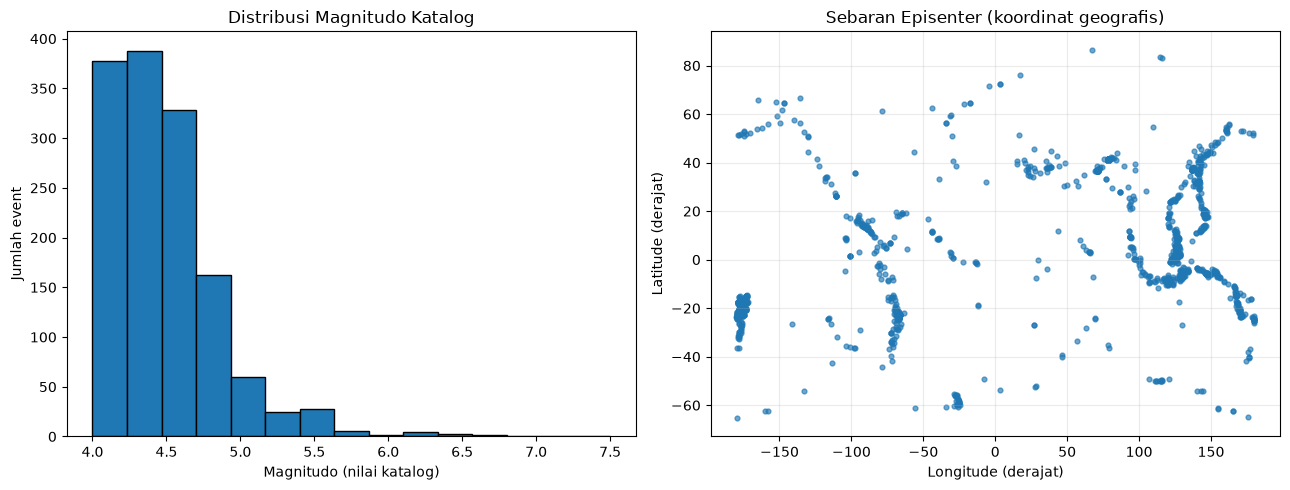

Grafik tersimpan: D:\TUGAS KULIAH\SEMESTER V\AI\hasil_usgs_gempa\ringkasan_katalog_gempa.png


In [16]:
if len(df):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    mags = df["magnitude"].dropna()
    axes[0].hist(mags, bins=15, edgecolor="black")
    axes[0].set_title("Distribusi Magnitudo Katalog")
    axes[0].set_xlabel("Magnitudo (nilai katalog)")
    axes[0].set_ylabel("Jumlah event")

    valid_xy = df.dropna(subset=["longitude_deg", "latitude_deg"])
    axes[1].scatter(valid_xy["longitude_deg"], valid_xy["latitude_deg"], s=12, alpha=0.65)
    axes[1].set_title("Sebaran Episenter (koordinat geografis)")
    axes[1].set_xlabel("Longitude (derajat)")
    axes[1].set_ylabel("Latitude (derajat)")
    axes[1].grid(True, alpha=0.25)

    plt.tight_layout()
    figure_path = OUT_DIR / "ringkasan_katalog_gempa.png"
    fig.savefig(figure_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Grafik tersimpan:", figure_path.resolve())
else:
    print("Tidak ada event pada query ini; grafik tidak dibuat.")

## 9. Ringkasan hasil dan batas interpretasi

Jalankan sel ini setelah retrieval dan pemeriksaan selesai. Angka ringkasan berasal dari respons API pada saat notebook dijalankan.

In [17]:
if len(df):
    summary = {
        "jumlah_event": int(len(df)),
        "rentang_waktu_utc": [
            str(df["time_utc"].min()),
            str(df["time_utc"].max())
        ],
        "magnitudo_min": float(df["magnitude"].min()) if df["magnitude"].notna().any() else None,
        "magnitudo_maks": float(df["magnitude"].max()) if df["magnitude"].notna().any() else None,
        "kedalaman_min_km": float(df["depth_km"].min()) if df["depth_km"].notna().any() else None,
        "kedalaman_maks_km": float(df["depth_km"].max()) if df["depth_km"].notna().any() else None,
        "jumlah_magnitude_type": int(df["magnitude_type"].nunique(dropna=True)),
        "checks": checks,
    }
    summary_path = OUT_DIR / "summary.json"
    summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
    print(json.dumps(summary, indent=2, ensure_ascii=False))
    print("\nRingkasan tersimpan:", summary_path.resolve())
else:
    print("Tidak ada data untuk diringkas.")

{
  "jumlah_event": 1389,
  "rentang_waktu_utc": [
    "2024-01-01 00:37:09.096000+00:00",
    "2024-01-31 23:43:17.478000+00:00"
  ],
  "magnitudo_min": 4.0,
  "magnitudo_maks": 7.5,
  "kedalaman_min_km": 1.147,
  "kedalaman_maks_km": 659.944,
  "jumlah_magnitude_type": 7,
  "checks": {
    "feature_count_matches_rows": true,
    "event_id_unique": true,
    "latitude_in_range": true,
    "longitude_in_range": true,
    "has_events": true
  }
}

Ringkasan tersimpan: D:\TUGAS KULIAH\SEMESTER V\AI\hasil_usgs_gempa\summary.json


## 10. Kesimpulan

Notebook ini mengimplementasikan **R-RET-001** dari buku: mengambil respons API, mempertahankan raw JSON, menormalisasi data ke CSV, mencatat provenance, dan melakukan optional checks. Hasil live hanya terbentuk ketika notebook benar-benar dijalankan dengan koneksi internet yang berhasil.

**Keterbatasan:** katalog dapat direvisi; event yang tercakup bergantung pada waktu, parameter query, dan cakupan layanan. Distribusi magnitudo serta sebaran episenter tidak cukup untuk menyimpulkan bahaya seismik, mekanisme sumber, atau dampak di suatu wilayah. Untuk laporan akademik, catat waktu eksekusi dan periksa ulang metadata sumber.